In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
sex_colors = {"Female": "#e67e22", "Male": "#2980b9"}  # same colors in every chart

df = pd.read_csv("cleaned_dataset.csv")
df["Outcome"] = df["Survived"].map({0: "Died", 1: "Survived"})
df["Sex"] = df["Sex"].str.title()
df["Class"] = df["Pclass"].map({1: "1st Class", 2: "2nd Class", 3: "3rd Class"})
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Adult (19-60)", "Senior (60+)"])
order = ["1st Class", "2nd Class", "3rd Class"]

Chart 1: The big picture. Of 891 passengers, 549 died and 342 survived, so only 38% survived. A count bar chart shows the totals$0

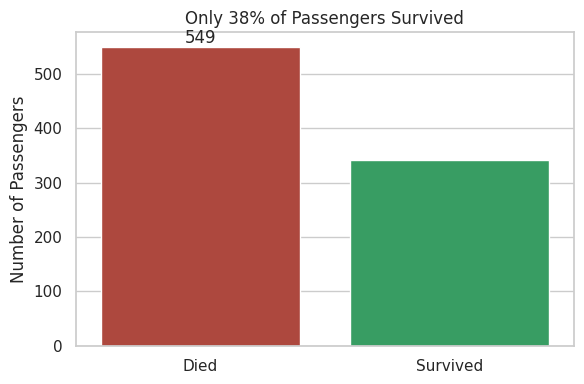

In [2]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Outcome", data=df, order=["Died", "Survived"],
                   hue="Outcome", palette=["#c0392b", "#27ae60"], legend=False)
ax.bar_label(ax.containers[0])
plt.title("Only 38% of Passengers Survived")
plt.xlabel("")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.savefig("01_overall_survival.png")
plt.show()

Chart 2: First clue, sex. A bar chart of survival rate (the share who survived) compares women and men.

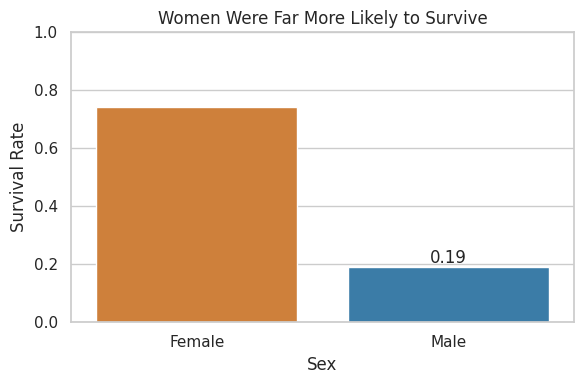

In [3]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(x="Sex", y="Survived", data=df, order=["Female", "Male"],
                 errorbar=None, hue="Sex", palette=sex_colors, legend=False)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Women Were Far More Likely to Survive")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("02_survival_by_sex.png")
plt.show()

Chart 3: Second clue, ticket class. The richer the ticket, the better the chance of survival.

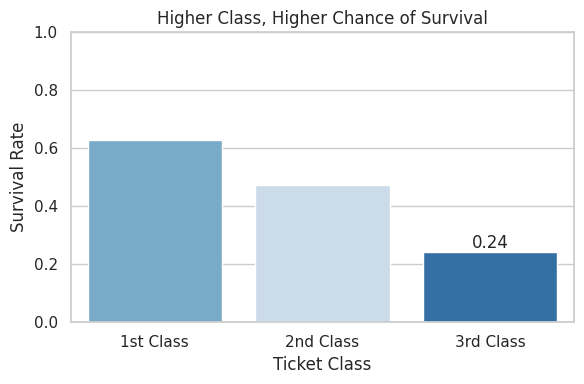

In [4]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(x="Class", y="Survived", data=df, order=order,
                 errorbar=None, hue="Class", palette="Blues_r", legend=False)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Higher Class, Higher Chance of Survival")
plt.xlabel("Ticket Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("03_survival_by_class.png")
plt.show()

Chart 4: Putting the clues together. A grouped bar chart shows sex and class at the same time.

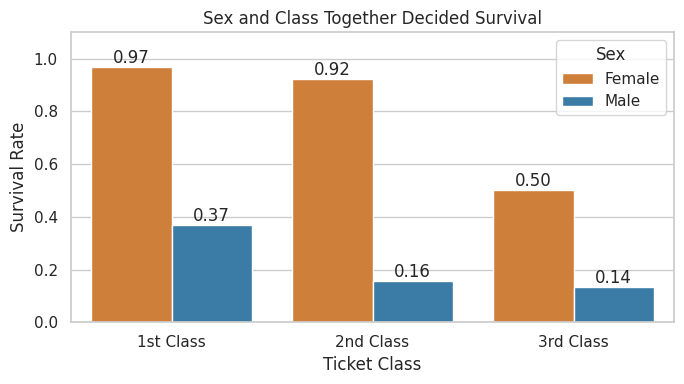

In [5]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x="Class", y="Survived", hue="Sex", hue_order=["Female", "Male"],
                 data=df, order=order, errorbar=None, palette=sex_colors)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.title("Sex and Class Together Decided Survival")
plt.xlabel("Ticket Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1.1)
plt.legend(title="Sex")
plt.tight_layout()
plt.savefig("04_sex_and_class.png")
plt.show()

Chart 5: Age. Children had the best odds, and survival falls as age rises.

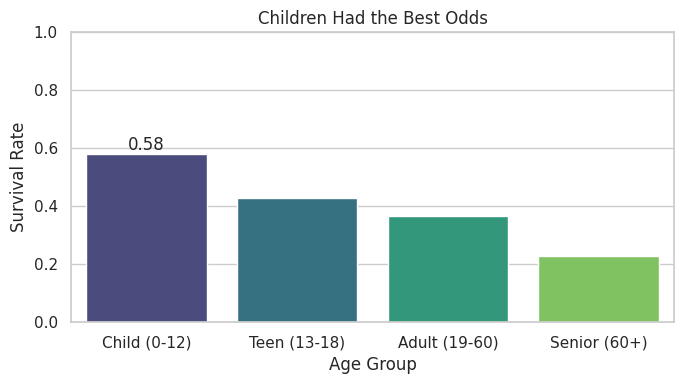

In [6]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(x="AgeGroup", y="Survived", data=df, errorbar=None,
                 hue="AgeGroup", palette="viridis", legend=False)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Children Had the Best Odds")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("05_survival_by_age.png")
plt.show()

Chart 6: The full picture. A heatmap shows the survival rate for every sex and class combination in one view. Green means high survival and red means low.

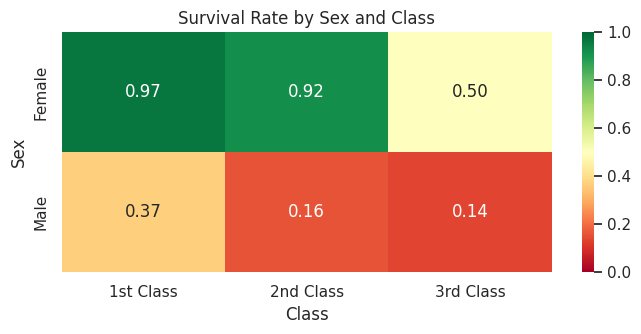

In [7]:
pivot = df.pivot_table(values="Survived", index="Sex", columns="Class", aggfunc="mean")[order]

plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Survival Rate by Sex and Class")
plt.tight_layout()
plt.savefig("06_heatmap.png")
plt.show()

## Download the charts

In [8]:
!zip -q charts.zip *.png

from google.colab import files
files.download("charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>